In [ ]:
pip install uproot awkward vector numpy matplotlib fsspec-xrootd

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 70.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fsspec-xrootd]


total de pares: 496132
massa do Z: 90.781 +/- 0.117 GeV
largura:    2.442 +/- 0.117 GeV
altura:     31397.295 +/- 1304.983


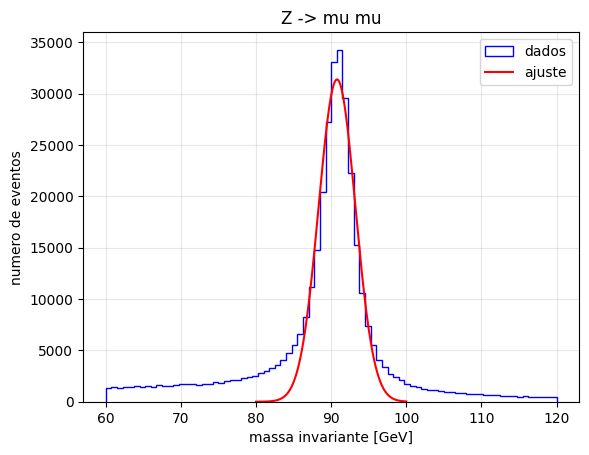

In [ ]:
import numpy as np
import awkward as ak #trabalhar com arrays de tamanho variavel por evento
import vector #trabalhar com quadrivetores
import uproot #trabalhar com extensão root em python
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

vector.register_awkward() #pré requisito pra o vector e awkwards se entenderem na soma dos quadrivetores

arquivo = "root://eospublic.cern.ch//eos/opendata/cms/Run2016H/DoubleMuon/NANOAOD/UL2016_MiniAODv2_NanoAODv9-v1/2510000/127C2975-1B1C-A046-AABF-62B77E757A86.root"


#calcula a gaussiana
def gaussiana(x, altura, media, sigma):
    return altura * np.exp(-((x - media) ** 2) / (2 * sigma ** 2))


#classe geral da análise
class AnaliseZ:



    # abre o arquivo e pega as colunas dos múons
    def carregar_dados(self):
        arvore = uproot.open(arquivo)["Events"]
        dados = arvore.arrays(
            ["Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge"],
            library="ak"
        )
        # cortes: pt > 20 GeV e |eta| < 2.4
        selecao = (dados.Muon_pt > 20) & (np.abs(dados.Muon_eta) < 2.4)
        self.muons = dados[selecao]


    #calcular a massa invariante
    def calcular_massas(self):
        quadrivetores = ak.zip(
            {
                "pt": self.muons.Muon_pt,
                "eta": self.muons.Muon_eta,
                "phi": self.muons.Muon_phi,
                "mass": self.muons.Muon_mass,
            },
            with_name="Momentum4D") #dizendo pro vector q é um quadrimomento


        # forma os pares de múons
        pares = ak.combinations(quadrivetores, 2, fields=["mu1", "mu2"])

        # cria a condição de cargas opostas
        cargas = ak.combinations(self.muons.Muon_charge, 2, fields=["q1", "q2"])
        opostas = cargas.q1 != cargas.q2

        #calcula a massa e aplica a condição de carga oposta
        mass = (pares[opostas].mu1 + pares[opostas].mu2).mass #array de arrays (awkwards)
        self.Massas = ak.to_numpy(ak.flatten(mass, axis=None)) #array unico (numpy)
        print("total de pares:", len(self.Massas))



    #plot e fit
    def ajustar_e_plotar(self):

        cont, bordas = np.histogram(self.Massas, bins=80, range=(60, 120)) #contagem/bin e bordas dos bins
        centros = (bordas[1:] + bordas[:-1]) / 2

        # faz o fit so na regiao do pico
        regiao = (centros > 80) & (centros < 100)
        parametros, pcov = curve_fit(gaussiana, centros[regiao], cont[regiao], p0=[100, 91, 3])

        altura = parametros[0]
        media  = parametros[1]
        sigma  = parametros[2]

        # incerteza = raiz quadrada da variância (diagonal da matriz)
        erro_altura = np.sqrt(pcov[0, 0])
        erro_media  = np.sqrt(pcov[1, 1])
        erro_sigma  = np.sqrt(pcov[2, 2])

        print(f"massa do Z: {media:.3f} +/- {erro_media:.3f} GeV")
        print(f"largura:    {sigma:.3f} +/- {erro_sigma:.3f} GeV")
        print(f"altura:     {altura:.3f} +/- {erro_altura:.3f}")

        # desenha o histograma
        plt.hist(self.Massas, bins=80, range=(60, 120),
                histtype="step", color="blue", label="dados")

        # desenha a curva do fit em cima
        x = np.linspace(80, 100, 200)
        y = gaussiana(x, altura, media, sigma)
        plt.plot(x, y, color="red", label="ajuste")

        plt.xlabel("massa invariante [GeV]")
        plt.ylabel("numero de eventos")
        plt.title("Z -> mu mu")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.savefig("zmumu.png")
        plt.show()

    def executar(self):
        self.carregar_dados()
        self.calcular_massas()
        self.ajustar_e_plotar()


analise = AnaliseZ()
analise.executar()